# Triagem de diabetes: modelos, calibração e limiar

Notebook de estudo da segunda vertente do projeto. A partir de respostas que uma pessoa sabe **antes** de qualquer diagnóstico, estimar a probabilidade de ela já ter ouvido de um profissional de saúde que tem diabetes — e decidir a partir de que probabilidade vale encaminhá-la para um exame de glicemia. Compara três baselines (prevalência, só o IMC e regressão logística) com XGBoost e LightGBM, mede o peso de cada grupo de entradas, o efeito do desbalanceamento (com e sem SMOTE) e da calibração, e fecha o limiar com critério escrito.

Autor: **Vinícius Ventura**.

> Os dados exibidos são respostas reais e anonimizadas de uma pesquisa pública de saúde dos Estados Unidos (BRFSS 2015, CDC) e servem apenas para demonstração. Nenhum registro identifica uma pessoa. Esta ferramenta é de triagem e não substitui avaliação clínica.

A proveniência do conjunto (repositório público, DOI, conjunto de origem, licença e as quatro divergências entre a página e o arquivo) está em `../data/bruto/diabetes/FONTE.md`; o significado de cada coluna, em `../docs/dicionario-de-dados-diabetes.md`. O notebook lê o CSV diretamente — é um documento de estudo e precisa rodar numa máquina limpa, sem banco — e não grava artefato nenhum: o modelo servido é produto do CLI (`python -m app.diabetes.treino`), que reproduz o que a seção "O que fica congelado para o CLI" registra.

Esta prosa não carrega número medido: todo número sai das saídas das células, que o *Run All* regenera.

## Dados e preparação

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from matplotlib.ticker import PercentFormatter
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier

pio.renderers.default = 'plotly_mimetype'  # só o JSON da figura: o módulo Estudos desenha com Plotly vivo
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.float_format', lambda v: f'{v:.4f}')

SEMENTE = 42
CSV = Path('../data/bruto/diabetes/cdc_diabetes_health_indicators.csv')

# 1. Renomeação das colunas na ordem do CSV (o ID, que é a posição da linha, passa intocado)
colunas_map = {
    'Diabetes_binary': 'Diabetes',
    'HighBP': 'Pressao_Alta',
    'HighChol': 'Colesterol_Alto',
    'CholCheck': 'Exame_Colesterol_5_Anos',
    'BMI': 'IMC',
    'Smoker': 'Fumou_100_Cigarros',
    'Stroke': 'Teve_AVC',
    'HeartDiseaseorAttack': 'Doenca_Coronariana_Ou_Infarto',
    'PhysActivity': 'Atividade_Fisica_30_Dias',
    'Fruits': 'Fruta_Diaria',
    'Veggies': 'Verdura_Diaria',
    'HvyAlcoholConsump': 'Consumo_Pesado_Alcool',
    'AnyHealthcare': 'Cobertura_Saude',
    'NoDocbcCost': 'Deixou_Medico_Por_Custo',
    'GenHlth': 'Saude_Geral',
    'MentHlth': 'Dias_Saude_Mental_Ruim',
    'PhysHlth': 'Dias_Saude_Fisica_Ruim',
    'DiffWalk': 'Dificuldade_Caminhar',
    'Sex': 'Sexo',
    'Age': 'Faixa_Etaria',
    'Education': 'Escolaridade',
    'Income': 'Faixa_Renda',
}

# 2. Tradução dos códigos 0/1 para o domínio em português (dicionário de dados)
BINARIAS = [
    'Pressao_Alta', 'Colesterol_Alto', 'Exame_Colesterol_5_Anos', 'Fumou_100_Cigarros', 'Teve_AVC',
    'Doenca_Coronariana_Ou_Infarto', 'Atividade_Fisica_30_Dias', 'Fruta_Diaria', 'Verdura_Diaria',
    'Consumo_Pesado_Alcool', 'Cobertura_Saude', 'Deixou_Medico_Por_Custo', 'Dificuldade_Caminhar',
]
sim_nao = {0: 'Não', 1: 'Sim'}
traducoes = {coluna: sim_nao for coluna in ['Diabetes', *BINARIAS]} | {'Sexo': {0: 'Feminino', 1: 'Masculino'}}

bruto = pd.read_csv(CSV)
df = bruto.rename(columns=colunas_map)
for coluna, mapa in traducoes.items():
    df[coluna] = df[coluna].map(mapa)
df['IMC'] = df['IMC'].astype('float64')
df.head()

,ID,Diabetes,Pressao_Alta,Colesterol_Alto,Exame_Colesterol_5_Anos,IMC,Fumou_100_Cigarros,Teve_AVC,Doenca_Coronariana_Ou_Infarto,Atividade_Fisica_30_Dias,...,Cobertura_Saude,Deixou_Medico_Por_Custo,Saude_Geral,Dias_Saude_Mental_Ruim,Dias_Saude_Fisica_Ruim,Dificuldade_Caminhar,Sexo,Faixa_Etaria,Escolaridade,Faixa_Renda
0,0,Não,Sim,Sim,Sim,40.0000,Sim,Não,Não,Não,...,Sim,Não,5,18,15,Sim,Feminino,9,4,3
1,1,Não,Não,Não,Não,25.0000,Sim,Não,Não,Sim,...,Não,Sim,3,0,0,Não,Feminino,7,6,1
2,2,Não,Sim,Sim,Sim,28.0000,Não,Não,Não,Não,...,Sim,Sim,5,30,30,Sim,Feminino,9,4,8
3,3,Não,Sim,Não,Sim,27.0000,Não,Não,Não,Sim,...,Sim,Não,2,0,0,Não,Feminino,11,3,6
4,4,Não,Sim,Sim,Sim,24.0000,Não,Não,Não,Sim,...,Sim,Não,2,3,0,Não,Feminino,11,5,4


In [2]:
# Paridade notebook <-> backend: a preparação acima e a de app/diabetes/dominio/features.py produzem o
# MESMO DataFrame, e o arredondamento do IMC que o pipeline aplica é o mesmo dos dois lados (e neutro
# na base, onde o IMC já é inteiro). Com o venv do backend (uv sync) o pacote `app` já está
# importável; noutro ambiente, instale-o antes desta célula: pip install -e ../backend
def arredondar_imc(quadro):
    quadro = quadro.copy()
    quadro['IMC'] = np.round(quadro['IMC'].astype('float64'))
    return quadro


try:
    from app.diabetes.dominio.features import arredondar_imc as _arredondar_backend
    from app.diabetes.dominio.features import preparar_base as _preparar_backend

    pd.testing.assert_frame_equal(df, _preparar_backend(bruto))
    teste_imc = pd.DataFrame({'IMC': [26.5, 27.5, 26.49, 26.51, 30.0]})
    pd.testing.assert_frame_equal(arredondar_imc(teste_imc), _arredondar_backend(teste_imc))
    pd.testing.assert_frame_equal(arredondar_imc(df), df)
    print('paridade notebook <-> backend: OK')
except ImportError:
    print('pacote `app` fora do ambiente: paridade não conferida nesta execução')

paridade notebook <-> backend: OK


In [3]:
VARIAVEIS = [c for c in df.columns if c not in ('ID', 'Diabetes')]
print('dimensões:', df.shape)
print('nulos:', int(df.isnull().sum().sum()))
print('linhas que repetem outra (alvo e 21 variáveis):', int(df.drop(columns='ID').duplicated().sum()))
print('perfis distintos nas 21 variáveis:', int(len(df[VARIAVEIS].drop_duplicates())))
contagem = df['Diabetes'].value_counts().reindex(['Não', 'Sim'])
pd.DataFrame({'n': contagem, '%': 100 * contagem / len(df)})

dimensões: (253680, 23)
nulos: 0


linhas que repetem outra (alvo e 21 variáveis): 24206
perfis distintos nas 21 variáveis: 227908


,n,%
Diabetes,,
Não,218334,86.0667
Sim,35346,13.9333


As linhas repetidas não são cópia: são pessoas diferentes que deram as mesmas respostas, num questionário de respostas curtas. Elas não vazam informação do treino para o teste — mas avisam que muitas pessoas são indistinguíveis para qualquer modelo, e que há um teto para o que dá para separar com estas perguntas.

## Exploração

Prevalência de diabetes por fator, com intervalo de confiança de 95 % (Wilson). É **associação na base, não causa**: o desenho é transversal e o alvo é o diagnóstico recebido — quem já sabe que tem diabetes pode ter mudado os hábitos depois disso.

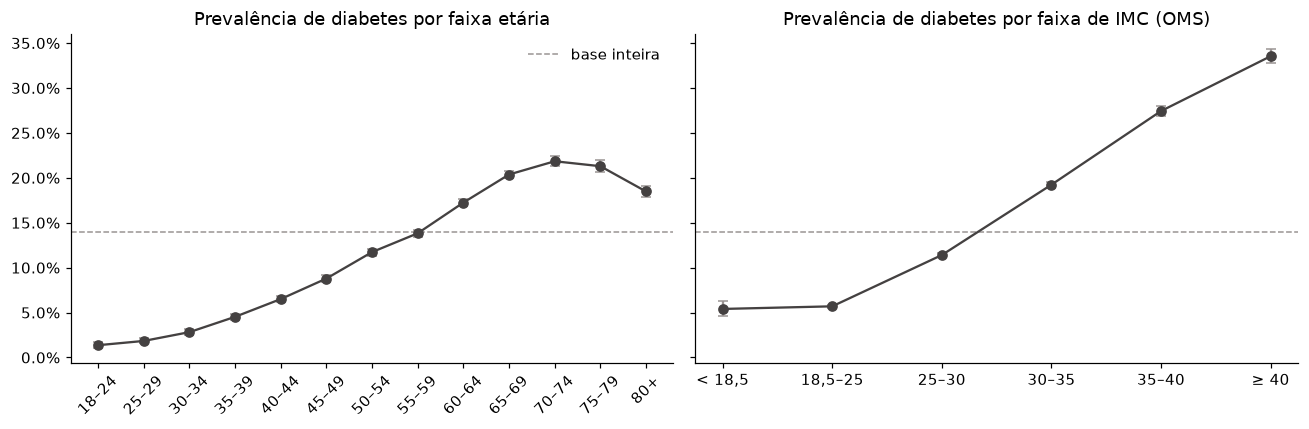

In [4]:
def prevalencia(alvo):
    n = len(alvo)
    k = int((alvo == 'Sim').sum())
    p = k / n if n else np.nan
    z = 1.96
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    meia = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return pd.Series({'n': n, 'prevalencia': p, 'ic_inf': centro - meia, 'ic_sup': centro + meia})


ROTULO_IDADE = {
    1: '18–24', 2: '25–29', 3: '30–34', 4: '35–39', 5: '40–44', 6: '45–49', 7: '50–54',
    8: '55–59', 9: '60–64', 10: '65–69', 11: '70–74', 12: '75–79', 13: '80+',
}
FAIXAS_IMC = ['< 18,5', '18,5–25', '25–30', '30–35', '35–40', '≥ 40']
faixa_imc = pd.cut(df['IMC'], [0, 18.5, 25, 30, 35, 40, np.inf], right=False, labels=FAIXAS_IMC)
geral = (df['Diabetes'] == 'Sim').mean()

por_idade = df.groupby('Faixa_Etaria')['Diabetes'].apply(prevalencia).unstack()
por_imc = df.groupby(faixa_imc, observed=True)['Diabetes'].apply(prevalencia).unstack()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tabela, rotulos, titulo in (
    (ax1, por_idade, [ROTULO_IDADE[i] for i in por_idade.index], 'por faixa etária'),
    (ax2, por_imc, list(por_imc.index), 'por faixa de IMC (OMS)'),
):
    x = np.arange(len(tabela))
    ax.errorbar(x, tabela['prevalencia'], yerr=[tabela['prevalencia'] - tabela['ic_inf'], tabela['ic_sup'] - tabela['prevalencia']],
                fmt='o-', color='#444141', ecolor='#9a9493', capsize=3)
    ax.axhline(geral, color='#9a9493', linestyle='--', linewidth=1, label='base inteira')
    ax.set_xticks(x, rotulos, rotation=45 if len(x) > 8 else 0)
    ax.set_title(f'Prevalência de diabetes {titulo}')
ax1.yaxis.set_major_formatter(PercentFormatter(1.0))
ax1.legend(frameon=False)
plt.tight_layout()
plt.show()

In [5]:
por_idade_sexo = (
    df.groupby(['Faixa_Etaria', 'Sexo'])['Diabetes']
    .apply(lambda alvo: (alvo == 'Sim').mean())
    .rename('prevalencia')
    .reset_index()
)
por_idade_sexo['faixa etária'] = por_idade_sexo['Faixa_Etaria'].map(ROTULO_IDADE)
figura = px.line(
    por_idade_sexo, x='faixa etária', y='prevalencia', color='Sexo', markers=True,
    title='Prevalência de diabetes por faixa etária e sexo',
    labels={'prevalencia': 'com diabetes'},
    color_discrete_map={'Feminino': '#d4752a', 'Masculino': '#3567a8'},
)
figura.update_yaxes(tickformat='.0%')
figura.show()

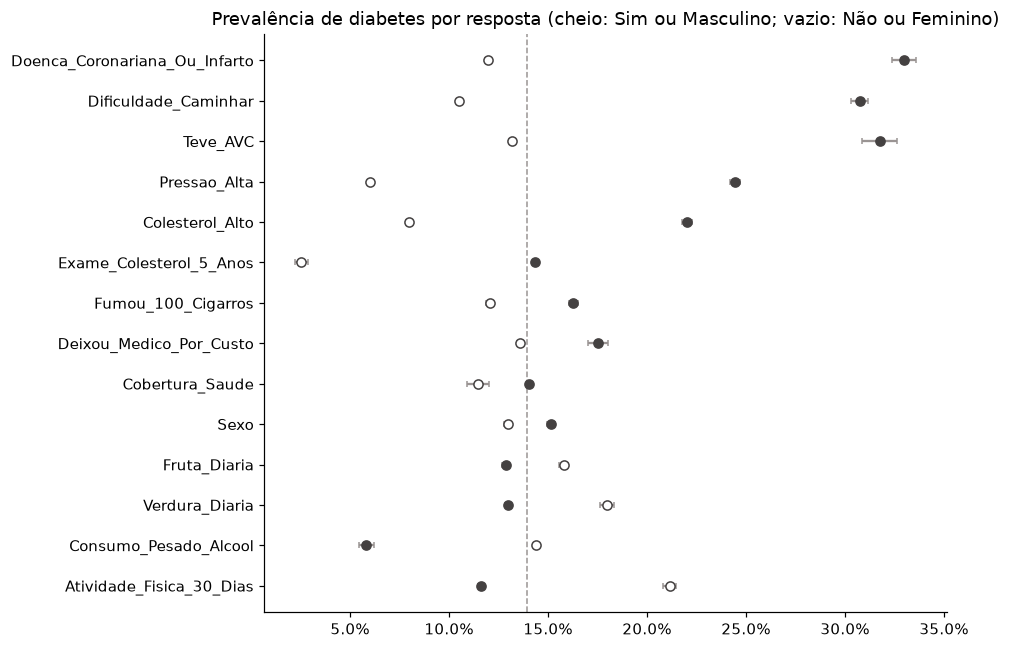

,variável,resposta,n,prevalencia,ic_inf,ic_sup
0,Pressao_Alta,Não,144851.0000,0.0604,0.0591,0.0616
1,Pressao_Alta,Sim,108829.0000,0.2445,0.2419,0.2470
2,Colesterol_Alto,Não,146089.0000,0.0798,0.0784,0.0812
3,Colesterol_Alto,Sim,107591.0000,0.2201,0.2177,0.2226
4,Exame_Colesterol_5_Anos,Não,9470.0000,0.0254,0.0225,0.0288
5,Exame_Colesterol_5_Anos,Sim,244210.0000,0.1437,0.1424,0.1451
6,Fumou_100_Cigarros,Não,141257.0000,0.1206,0.1189,0.1223
7,Fumou_100_Cigarros,Sim,112423.0000,0.1629,0.1608,0.1651
8,Teve_AVC,Não,243388.0000,0.1318,0.1305,0.1331
9,Teve_AVC,Sim,10292.0000,0.3175,0.3086,0.3266


In [6]:
linhas = []
for coluna in [*BINARIAS, 'Sexo']:
    for valor in sorted(df[coluna].unique()):
        linhas.append({'variável': coluna, 'resposta': valor, **prevalencia(df.loc[df[coluna] == valor, 'Diabetes'])})
fatores = pd.DataFrame(linhas)

ordem = (
    fatores.pivot(index='variável', columns='resposta', values='prevalencia')
    .assign(diferenca=lambda t: t['Sim'].fillna(t.get('Masculino')) - t['Não'].fillna(t.get('Feminino')))
    .sort_values('diferenca')
    .index.tolist()
)
fig, ax = plt.subplots(figsize=(9, 6))
for i, variavel in enumerate(ordem):
    sub = fatores[fatores['variável'] == variavel]
    for _, linha in sub.iterrows():
        cheio = linha['resposta'] in ('Sim', 'Masculino')
        ax.errorbar(linha['prevalencia'], i, xerr=[[linha['prevalencia'] - linha['ic_inf']], [linha['ic_sup'] - linha['prevalencia']]],
                    fmt='o', mfc='#444141' if cheio else 'white', mec='#444141', ecolor='#9a9493', capsize=2)
ax.axvline(geral, color='#9a9493', linestyle='--', linewidth=1)
ax.set_yticks(range(len(ordem)), ordem)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title('Prevalência de diabetes por resposta (cheio: Sim ou Masculino; vazio: Não ou Feminino)')
plt.tight_layout()
plt.show()
fatores.round(4)

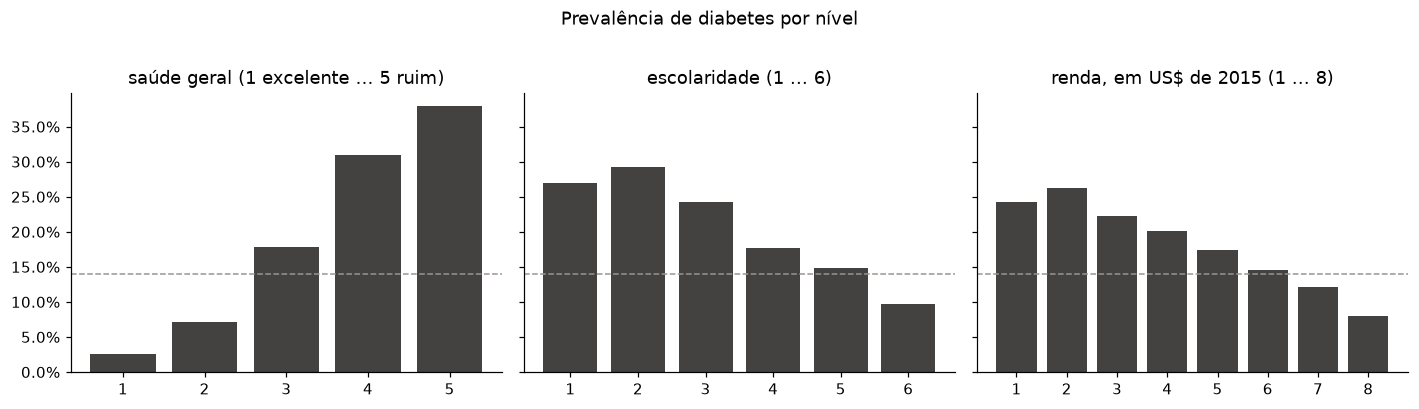

In [7]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, coluna, titulo in (
    (eixos[0], 'Saude_Geral', 'saúde geral (1 excelente … 5 ruim)'),
    (eixos[1], 'Escolaridade', 'escolaridade (1 … 6)'),
    (eixos[2], 'Faixa_Renda', 'renda, em US$ de 2015 (1 … 8)'),
):
    tabela = df.groupby(coluna)['Diabetes'].apply(prevalencia).unstack()
    ax.bar(tabela.index.astype(str), tabela['prevalencia'], color='#444141')
    ax.axhline(geral, color='#9a9493', linestyle='--', linewidth=1)
    ax.set_title(titulo)
eixos[0].yaxis.set_major_formatter(PercentFormatter(1.0))
plt.suptitle('Prevalência de diabetes por nível', y=1.02)
plt.tight_layout()
plt.show()

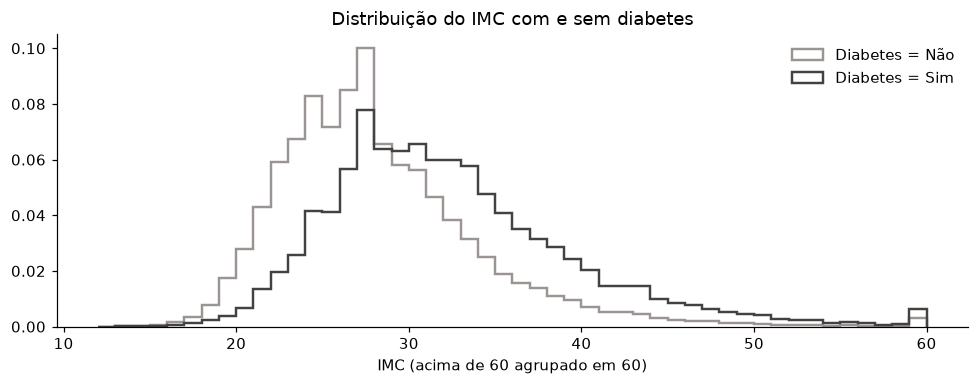

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for valor, cor in (('Não', '#9a9493'), ('Sim', '#444141')):
    ax.hist(df.loc[df['Diabetes'] == valor, 'IMC'].clip(upper=60), bins=np.arange(12, 61, 1), density=True,
            histtype='step', linewidth=1.6, color=cor, label=f'Diabetes = {valor}')
ax.set_xlabel('IMC (acima de 60 agrupado em 60)')
ax.set_title('Distribuição do IMC com e sem diabetes')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### O que a exploração mostra

- A prevalência sobe com a idade até a faixa dos setenta e poucos anos e recua um pouco nas mais altas — possivelmente sobrevivência: quem convive com a diabetes há décadas sai mais cedo da população que responde à pesquisa. Sobe com o IMC em toda a escala da OMS, e os homens ficam um pouco acima das mulheres.
- Pressão alta e colesterol alto têm diferenças grandes e são fatores conhecidos. AVC, doença coronariana, dificuldade de caminhar e saúde geral ruim também têm — mas são complicações ou consequências da doença, não antecedentes dela.
- Três associações apontam para o lado que uma triagem não pode ensinar: **álcool pesado** com prevalência menor (quem recebe o diagnóstico é orientado a parar de beber) e **ter cobertura de saúde** e **ter medido o colesterol** com prevalência maior (o diagnóstico exige contato com o sistema de saúde). São marcas do diagnóstico, não do risco.
- Escolaridade e renda têm gradiente claro: a prevalência cai, de modo geral, à medida que sobem — os determinantes sociais aparecem mesmo numa base sem pesos.

A seção seguinte transforma essas leituras em decisão sobre as entradas.

## Entradas: o que se sabe antes do diagnóstico

O caso de uso é a triagem de quem **ainda não tem** diagnóstico. Uma variável entra no modelo se: (1) uma pessoa sem diagnóstico consegue respondê-la; (2) a associação dela com o alvo não é, principalmente, consequência do diagnóstico ou do acesso a ele; (3) ela faz sentido para quem responde ao simulador, no Brasil. Os grupos que ficam de fora:

- **consequências** — saúde geral, dias de saúde mental e física ruins, dificuldade de caminhar: descrevem o efeito da doença (e de saber dela);
- **acesso ao diagnóstico** — cobertura de saúde, deixar de ir ao médico por custo, ter medido o colesterol: predizem "foi diagnosticado", não "tem diabetes" — o modelo daria risco menor a quem não vai ao médico, que é justamente quem a triagem procura;
- **complicações** — AVC, doença coronariana ou infarto: são complicações da própria diabetes, e quem as tem já está em acompanhamento;
- **álcool pesado** — a associação aponta para o lado contrário do esperado (a exploração acima mostra): o simulador ensinaria que beber muito reduz o risco;
- **renda** — faixas em dólares de 2015, sem tradução para quem usa o produto.

Ficam dez entradas. A decisão foi tomada antes desta medição; a tabela abaixo mede o custo de cada exclusão (validação cruzada de 5 dobras no **treino**, LightGBM numa configuração de referência) e confirma ou derruba a decisão.

In [9]:
ENTRADAS = [
    'Faixa_Etaria', 'Sexo', 'IMC', 'Pressao_Alta', 'Colesterol_Alto', 'Fumou_100_Cigarros',
    'Atividade_Fisica_30_Dias', 'Fruta_Diaria', 'Verdura_Diaria', 'Escolaridade',
]
GRUPOS = {
    'consequências': ['Saude_Geral', 'Dias_Saude_Mental_Ruim', 'Dias_Saude_Fisica_Ruim', 'Dificuldade_Caminhar'],
    'acesso ao diagnóstico': ['Cobertura_Saude', 'Deixou_Medico_Por_Custo', 'Exame_Colesterol_5_Anos'],
    'complicações': ['Teve_AVC', 'Doenca_Coronariana_Ou_Infarto'],
    'álcool pesado': ['Consumo_Pesado_Alcool'],
    'renda': ['Faixa_Renda'],
}

X = df[VARIAVEIS]
y = (df['Diabetes'] == 'Sim').astype(int).to_numpy()
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE, stratify=y)
dobras = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE).split(X_treino, y_treino))
print(f'treino: {len(X_treino)} linhas, prevalência {y_treino.mean():.4f}')
print(f'teste:  {len(X_teste)} linhas, prevalência {y_teste.mean():.4f}')

treino: 202944 linhas, prevalência 0.1393
teste:  50736 linhas, prevalência 0.1393


In [10]:
CATEGORIAS_TEXTO = {coluna: ['Não', 'Sim'] for coluna in BINARIAS} | {'Sexo': ['Feminino', 'Masculino']}
ESCALAS = {
    'Faixa_Etaria': list(range(1, 14)),
    'Escolaridade': list(range(1, 7)),
    'Saude_Geral': list(range(1, 6)),
    'Faixa_Renda': list(range(1, 9)),
}


def preprocessador(colunas, linear=False):
    # Árvores: Sim/Não e sexo em 0/1 (domínio explícito, desconhecido é erro), o resto como número.
    # Linear: as escalas em one-hot e as contínuas padronizadas.
    texto = [c for c in colunas if c in CATEGORIAS_TEXTO]
    resto = [c for c in colunas if c not in CATEGORIAS_TEXTO]
    codificar = ('texto', OrdinalEncoder(categories=[CATEGORIAS_TEXTO[c] for c in texto], handle_unknown='error'), texto)
    if not linear:
        return ColumnTransformer([codificar, ('numericas', 'passthrough', resto)])
    escalas = [c for c in resto if c in ESCALAS]
    continuas = [c for c in resto if c not in ESCALAS]
    return ColumnTransformer([
        codificar,
        ('escalas', OneHotEncoder(categories=[ESCALAS[c] for c in escalas], drop='first',
                                  handle_unknown='error', sparse_output=False), escalas),
        ('continuas', StandardScaler(), continuas),
    ])


def montar(estimador, colunas, linear=False, smote=False):
    passos = [('imc', FunctionTransformer(arredondar_imc)), ('colunas', preprocessador(colunas, linear))]
    if smote:
        passos.append(('sampler', SMOTE(random_state=SEMENTE)))  # dentro do pipeline: só no ajuste
    passos.append(('modelo', estimador))
    return ImbPipeline(passos) if smote else Pipeline(passos)


def validar(fabrica, colunas):
    # Validação cruzada nas MESMAS 5 dobras do treino: predições fora da dobra e métricas por dobra.
    fora_da_dobra = np.zeros(len(y_treino))
    por_dobra = []
    inicio = time.perf_counter()
    for indices_treino, indices_validacao in dobras:
        modelo = fabrica(colunas)
        modelo.fit(X_treino.iloc[indices_treino], y_treino[indices_treino])
        p = modelo.predict_proba(X_treino.iloc[indices_validacao])[:, 1]
        fora_da_dobra[indices_validacao] = p
        alvo = y_treino[indices_validacao]
        por_dobra.append([roc_auc_score(alvo, p), average_precision_score(alvo, p), brier_score_loss(alvo, p)])
    m = np.array(por_dobra)
    return fora_da_dobra, {
        'roc_auc': m[:, 0].mean(), 'roc_auc_dp': m[:, 0].std(ddof=1),
        'pr_auc': m[:, 1].mean(), 'pr_auc_dp': m[:, 1].std(ddof=1),
        'brier': m[:, 2].mean(), 'segundos': time.perf_counter() - inicio,
    }


def lgbm(**ajustes):
    parametros = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8,
                      subsample_freq=1, colsample_bytree=0.8, random_state=SEMENTE, n_jobs=8, verbose=-1)
    return LGBMClassifier(**(parametros | ajustes))


def xgb(**ajustes):
    parametros = dict(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                      objective='binary:logistic', eval_metric='logloss', tree_method='hist',
                      random_state=SEMENTE, n_jobs=8)
    return XGBClassifier(**(parametros | ajustes))

In [11]:
sem = lambda *grupos: [c for c in VARIAVEIS if c not in {v for g in grupos for v in GRUPOS[g]}]
conjuntos = {
    'todas as 21': VARIAVEIS,
    'sem consequências': sem('consequências'),
    'sem acesso ao diagnóstico': sem('acesso ao diagnóstico'),
    'sem complicações': sem('complicações'),
    'as 10 entradas': ENTRADAS,
    '10 + álcool pesado': ENTRADAS + GRUPOS['álcool pesado'],
    '10 + renda': ENTRADAS + GRUPOS['renda'],
    '10 + complicações': ENTRADAS + GRUPOS['complicações'],
    '10 sem escolaridade': [c for c in ENTRADAS if c != 'Escolaridade'],
    'mínimo: idade, sexo, IMC, pressão, colesterol, atividade': [
        'Faixa_Etaria', 'Sexo', 'IMC', 'Pressao_Alta', 'Colesterol_Alto', 'Atividade_Fisica_30_Dias'],
}
ab_entradas = pd.DataFrame([
    {'entradas': nome, 'n': len(colunas), **validar(lambda c: montar(lgbm(), c), colunas)[1]}
    for nome, colunas in conjuntos.items()
])
ab_entradas

,entradas,n,roc_auc,roc_auc_dp,pr_auc,pr_auc_dp,brier,segundos
0,todas as 21,21,0.8311,0.0021,0.4366,0.0064,0.0964,5.5024
1,sem consequências,17,0.8124,0.0021,0.4070,0.0071,0.0994,5.4800
2,sem acesso ao diagnóstico,18,0.8297,0.0022,0.4350,0.0079,0.0966,5.3100
3,sem complicações,19,0.8298,0.0025,0.4333,0.0084,0.0967,5.4041
4,as 10 entradas,10,0.7994,0.0024,0.3816,0.0082,0.1016,4.5728
5,10 + álcool pesado,11,0.8018,0.0023,0.3862,0.0079,0.1012,4.7826
6,10 + renda,11,0.8049,0.0022,0.3923,0.0073,0.1007,4.6568
7,10 + complicações,12,0.8046,0.0019,0.3938,0.0057,0.1006,4.9322
8,10 sem escolaridade,9,0.7961,0.0027,0.3774,0.0086,0.1020,4.7141
9,"mínimo: idade, sexo, IMC, pressão, colesterol,...",6,0.7946,0.0025,0.3759,0.0087,0.1022,4.2362


### Leitura

- Quase toda a distância entre as 21 variáveis e as dez entradas vem do grupo das **consequências**: saúde geral, dias ruins e dificuldade de caminhar carregam a doença, não a antecedem — o ganho que elas dão é o que o modelo não pode usar.
- **Acesso ao diagnóstico** e **complicações** quase não mudam a ordenação: tirá-los custa pouco e livra o modelo de aprender quem foi ao médico.
- Álcool pesado, renda e complicações, somados às dez, acrescentam pouco, e cada um traz o defeito já descrito: direção invertida, moeda e ano de outro país, consequência da doença.
- O conjunto mínimo de seis respostas já entrega quase tudo: pressão alta, IMC, idade e colesterol fazem o trabalho pesado. Frutas, verduras, fumo e escolaridade somam pouco, mas não atrapalham e são perguntas rápidas de responder.

A decisão se confirma: as dez entradas.

## Baselines e candidatos

Três baselines dão a régua: a **prevalência** (a mesma probabilidade para todos — o que um modelo inútil faria), **só o IMC** como escore (sem modelo nenhum, com a regra IMC ≥ 30 como ponto de corte de referência) e a **regressão logística** com as dez entradas. Contra eles, XGBoost e LightGBM, cada um numa grade pequena de hiperparâmetros.

**Critério de escolha**, fixado antes de ver os números: maior **PR-AUC** média na validação cruzada do treino — a métrica da classe que importa, que não se deixa inflar pela maioria de negativos. Empate (diferença para o melhor menor que o desvio-padrão do melhor entre as dobras) se resolve pelo menor Brier, arredondado a 4 casas, e depois pelo modelo mais simples (menos árvores, depois menos profundo).

In [12]:
def metricas_por_dobra(escore):
    # Para escores que não precisam de ajuste: as métricas nas mesmas dobras de validação.
    m = np.array([[roc_auc_score(y_treino[v], escore[v]), average_precision_score(y_treino[v], escore[v])] for _, v in dobras])
    return {'roc_auc': m[:, 0].mean(), 'roc_auc_dp': m[:, 0].std(ddof=1), 'pr_auc': m[:, 1].mean(), 'pr_auc_dp': m[:, 1].std(ddof=1)}


prevalencia_treino = y_treino.mean()
constante = np.full(len(y_treino), prevalencia_treino)
linhas = [
    {'modelo': 'prevalência', 'parametros': '-', **metricas_por_dobra(constante),
     'brier': brier_score_loss(y_treino, constante), 'segundos': 0.0},
    {'modelo': 'só o IMC (escore)', 'parametros': '-', **metricas_por_dobra(X_treino['IMC'].to_numpy()),
     'brier': np.nan, 'segundos': 0.0},
]
_, logistica = validar(lambda c: montar(LogisticRegression(max_iter=2000), c, linear=True), ENTRADAS)
linhas.append({'modelo': 'regressão logística', 'parametros': '-', **logistica})
baselines = pd.DataFrame(linhas)

regra = (X_treino['IMC'] >= 30).to_numpy()
print(f"regra IMC >= 30 no treino: recall {(regra & (y_treino == 1)).sum() / (y_treino == 1).sum():.4f}, "
      f"precisão {(regra & (y_treino == 1)).sum() / regra.sum():.4f}, encaminhados {regra.mean():.4f}")
baselines

regra IMC >= 30 no treino: recall 0.5853, precisão 0.2356, encaminhados 0.3461


,modelo,parametros,roc_auc,roc_auc_dp,pr_auc,pr_auc_dp,brier,segundos
0,prevalência,-,0.5000,0.0000,0.1393,0.0000,0.1199,0.0000
1,só o IMC (escore),-,0.6900,0.0074,0.2485,0.0058,NaN,0.0000
2,regressão logística,-,0.7932,0.0015,0.3641,0.0042,0.1031,3.2270


In [13]:
GRADES = {
    'XGBoost': (xgb, [dict(max_depth=d, n_estimators=n) for d in (3, 5) for n in (300, 600)]),
    'LightGBM': (lgbm, [dict(num_leaves=f, n_estimators=n) for f in (15, 31) for n in (300, 600)]),
}
candidatos = []
for familia, (fabrica, grade) in GRADES.items():
    for ajustes in grade:
        fora, r = validar(lambda c, f=fabrica, a=ajustes: montar(f(**a), c), ENTRADAS)
        candidatos.append({'modelo': familia, 'parametros': ajustes, **r, 'fora_da_dobra': fora})


def escolher(candidatos):
    melhor = max(candidatos, key=lambda c: c['pr_auc'])
    empatados = [c for c in candidatos if melhor['pr_auc'] - c['pr_auc'] < melhor['pr_auc_dp']]
    profundidade = lambda c: c['parametros'].get('max_depth', c['parametros'].get('num_leaves'))
    return min(empatados, key=lambda c: (round(c['brier'], 4), c['parametros']['n_estimators'], profundidade(c)))


escolhido = escolher(candidatos)
comparacao = pd.concat([
    baselines,
    pd.DataFrame([{k: v for k, v in c.items() if k != 'fora_da_dobra'} for c in candidatos]),
], ignore_index=True).sort_values('pr_auc', ascending=False, ignore_index=True)
print('escolhido:', escolhido['modelo'], escolhido['parametros'])
comparacao

escolhido: XGBoost {'max_depth': 3, 'n_estimators': 300}


,modelo,parametros,roc_auc,roc_auc_dp,pr_auc,pr_auc_dp,brier,segundos
0,XGBoost,"{'max_depth': 3, 'n_estimators': 300}",0.8002,0.0025,0.3847,0.0074,0.1014,5.0798
1,XGBoost,"{'max_depth': 3, 'n_estimators': 600}",0.8002,0.0025,0.3840,0.0074,0.1014,8.2072
2,LightGBM,"{'num_leaves': 15, 'n_estimators': 300}",0.8003,0.0024,0.3839,0.0074,0.1014,4.4116
3,XGBoost,"{'max_depth': 5, 'n_estimators': 300}",0.7998,0.0024,0.3821,0.0075,0.1015,5.5217
4,LightGBM,"{'num_leaves': 15, 'n_estimators': 600}",0.7995,0.0025,0.3818,0.0074,0.1016,6.6437
5,LightGBM,"{'num_leaves': 31, 'n_estimators': 300}",0.7994,0.0024,0.3816,0.0082,0.1016,4.7743
6,XGBoost,"{'max_depth': 5, 'n_estimators': 600}",0.7985,0.0026,0.3784,0.0077,0.1018,9.2995
7,LightGBM,"{'num_leaves': 31, 'n_estimators': 600}",0.7978,0.0024,0.3781,0.0079,0.1019,7.4567
8,regressão logística,-,0.7932,0.0015,0.3641,0.0042,0.1031,3.2270
9,só o IMC (escore),-,0.6900,0.0074,0.2485,0.0058,NaN,0.0000


### Leitura

- O IMC sozinho já ordena melhor que o acaso, mas fica longe de qualquer modelo; a regra IMC ≥ 30 encaminharia uma fração grande da base e ainda deixaria muita gente com diabetes de fora.
- A regressão logística, com as mesmas dez entradas, chega perto dos boosters, mas fica abaixo deles por mais que o ruído entre dobras.
- Entre XGBoost e LightGBM, e entre as configurações da grade, as diferenças de PR-AUC ficam dentro do desvio-padrão entre dobras: pelo critério, é empate, e o desempate pelo Brier e pela simplicidade escolhe o **XGBoost raso, com menos árvores**. Árvores mais fundas ou mais numerosas não ganham nada: com dez respostas curtas, não há interação complexa a aprender.

## Desbalanceamento: nada, peso de classe ou SMOTE

A classe positiva é minoria, e há três tratamentos comuns: **nenhum**, **peso de classe** (`scale_pos_weight` = negativos ÷ positivos) e **SMOTE** dentro do pipeline (só no ajuste de cada dobra, nunca na validação). O SMOTE comum interpola também as respostas codificadas e cria pessoas com "meio sim" ou "meio masculino" — mais uma razão para só usá-lo com ganho medido. Critério: o mesmo da comparação de candidatos; reponderar a classe tende a não mudar a ordenação e a piorar a calibração, e o Brier mostra isso.

In [14]:
fabrica_escolhida = dict(XGBoost=xgb, LightGBM=lgbm)[escolhido['modelo']]
ajustes_escolhidos = escolhido['parametros']
razao = (y_treino == 0).sum() / (y_treino == 1).sum()
TRATAMENTOS = {
    'nenhum': lambda c: montar(fabrica_escolhida(**ajustes_escolhidos), c),
    'peso de classe': lambda c: montar(fabrica_escolhida(**ajustes_escolhidos, scale_pos_weight=razao), c),
    'SMOTE': lambda c: montar(fabrica_escolhida(**ajustes_escolhidos), c, smote=True),
}
resultados_tratamento = {}
for nome, fabrica in TRATAMENTOS.items():
    resultados_tratamento[nome] = validar(fabrica, ENTRADAS)
desbalanceamento = pd.DataFrame([{'tratamento': nome, **r} for nome, (_, r) in resultados_tratamento.items()])
# O critério da comparação de candidatos: maior PR-AUC; empate (diferença menor que o desvio-padrão do melhor) pelo menor
# Brier e, depois, pelo tratamento mais simples (a ordem do dicionário).
r_melhor = max((r for _, r in resultados_tratamento.values()), key=lambda r: r['pr_auc'])
empatados = [n for n, (_, r) in resultados_tratamento.items() if r_melhor['pr_auc'] - r['pr_auc'] < r_melhor['pr_auc_dp']]
tratamento = min(empatados, key=lambda n: (round(resultados_tratamento[n][1]['brier'], 4), list(TRATAMENTOS).index(n)))
print('tratamento escolhido:', tratamento)
desbalanceamento

tratamento escolhido: nenhum


,tratamento,roc_auc,roc_auc_dp,pr_auc,pr_auc_dp,brier,segundos
0,nenhum,0.8002,0.0025,0.3847,0.0074,0.1014,4.8339
1,peso de classe,0.8002,0.0024,0.3846,0.0074,0.1883,4.8667
2,SMOTE,0.7912,0.0016,0.3646,0.0063,0.1323,10.1149


### Leitura

O peso de classe não muda a ordenação e destrói a calibração: o Brier quase dobra, porque o modelo passa a superestimar a probabilidade de todo mundo — e a tela mostraria um número que não quer dizer o que diz. O SMOTE piora as duas coisas. Fica **nenhum** tratamento: o desbalanceamento se resolve no limiar de triagem, mais adiante, que é onde a decisão de encaminhar mora.

## Calibração

A probabilidade que a tela mostra precisa dizer o que diz: entre as pessoas a quem o modelo atribui uma probabilidade *p*, a fração com diabetes deve ser *p*. Compara a probabilidade crua do modelo escolhido com a calibrada por regressão isotônica (`CalibratedClassifierCV`, ajustada dentro de cada dobra), pelo Brier e pela curva de confiabilidade em decis das predições fora da dobra. A calibração só entra se reduzir o Brier fora da dobra: com Brier igual, fica de fora — um passo a menos entre treino e serviço.

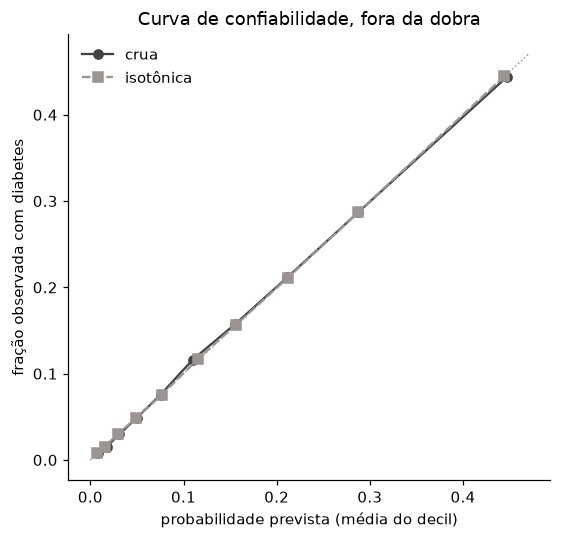

calibração isotônica entra: False


,probabilidade,roc_auc,roc_auc_dp,pr_auc,pr_auc_dp,brier,segundos
0,crua,0.8002,0.0025,0.3847,0.0074,0.1014,4.8339
1,isotônica,0.8002,0.0026,0.3843,0.0071,0.1014,13.2638


In [15]:
fabrica_final = TRATAMENTOS[tratamento]
fora_crua, r_crua = resultados_tratamento[tratamento]
fora_iso, r_iso = validar(lambda c: CalibratedClassifierCV(fabrica_final(c), method='isotonic', cv=3), ENTRADAS)
calibrar = r_iso['brier'] < r_crua['brier'] - 1e-4

fig, ax = plt.subplots(figsize=(5.2, 5))
limite = 0.0
for p, rotulo, estilo in ((fora_crua, 'crua', 'o-'), (fora_iso, 'isotônica', 's--')):
    observado, previsto = calibration_curve(y_treino, p, n_bins=10, strategy='quantile')
    ax.plot(previsto, observado, estilo, label=rotulo, color='#444141' if rotulo == 'crua' else '#9a9493')
    limite = max(limite, previsto.max(), observado.max())  # a diagonal até onde os decis chegam
limite *= 1.05
ax.plot([0, limite], [0, limite], ':', color='#9a9493', linewidth=1)
ax.set_xlabel('probabilidade prevista (média do decil)')
ax.set_ylabel('fração observada com diabetes')
ax.set_title('Curva de confiabilidade, fora da dobra')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
print('calibração isotônica entra:', calibrar)
pd.DataFrame([{'probabilidade': 'crua', **r_crua}, {'probabilidade': 'isotônica', **r_iso}])

### Leitura

A curva crua já acompanha a diagonal, e a isotônica não reduz o Brier: o XGBoost com perda logística, sem reponderação, entrega probabilidades calibradas na escala da base. A calibração fica de fora — um passo a menos entre o treino e o serviço. "Escala da base" quer dizer frequência entre os respondentes desta pesquisa, não na população (ver as limitações, no fim).

## Limiar de triagem

**Critério**, fixado antes de ver os números: o limiar é o **maior** valor de probabilidade cujo **recall**, nas predições fora da dobra do treino, ainda chega a **0,80** — quatro em cada cinco pessoas com diabetes encaminhadas para o exame. Recall primeiro porque deixar de encaminhar quem tem diabetes custa mais que um exame de glicemia a mais: a ação que a triagem sugere é barata e não invasiva. Fora da dobra porque o limiar não pode ser escolhido olhando o teste, que fica para a avaliação final. A tabela mostra o que outros alvos de recall custariam, para a escolha ficar à vista.

In [16]:
RECALL_ALVO = 0.80
fora_final = fora_iso if calibrar else fora_crua


def limiar_para_recall(alvo_y, p, recall_alvo):
    # O maior t tal que recall(p >= t) >= recall_alvo (empates em t entram todos no encaminhamento).
    ordem = np.argsort(-p, kind='mergesort')
    recall_acumulado = np.cumsum(alvo_y[ordem]) / alvo_y.sum()
    return float(p[ordem][np.argmax(recall_acumulado >= recall_alvo)])


def ponto_de_operacao(alvo_y, p, limiar):
    encaminhar = p >= limiar
    vp = int((encaminhar & (alvo_y == 1)).sum())
    fp = int((encaminhar & (alvo_y == 0)).sum())
    vn = int((~encaminhar & (alvo_y == 0)).sum())
    fn = int((~encaminhar & (alvo_y == 1)).sum())
    return {'limiar': limiar, 'recall': vp / (vp + fn), 'precisao': vp / (vp + fp), 'especificidade': vn / (vn + fp),
            'encaminhados': encaminhar.mean(), 'vp': vp, 'fp': fp, 'vn': vn, 'fn': fn}


pontos = pd.DataFrame([
    {'recall_alvo': alvo, **ponto_de_operacao(y_treino, fora_final, limiar_para_recall(y_treino, fora_final, alvo))}
    for alvo in (0.70, 0.75, 0.80, 0.85, 0.90)
])
LIMIAR = limiar_para_recall(y_treino, fora_final, RECALL_ALVO)
print(f'limiar escolhido (recall >= {RECALL_ALVO} fora da dobra): {LIMIAR:.6f}')
pontos

limiar escolhido (recall >= 0.8 fora da dobra): 0.125548


,recall_alvo,limiar,recall,precisao,especificidade,encaminhados,vp,fp,vn,fn
0,0.7000,0.1707,0.7000,0.3058,0.7427,0.3190,19794,44940,129727,8483
1,0.7500,0.1481,0.7500,0.2884,0.7004,0.3624,21208,52332,122335,7069
2,0.8000,0.1255,0.8000,0.2706,0.6508,0.4120,22622,60992,113675,5655
3,0.8500,0.1022,0.8500,0.2528,0.5934,0.4684,24036,71026,103641,4241
4,0.9000,0.0762,0.9000,0.2298,0.5115,0.5458,25450,85319,89348,2827


### Leitura

A tabela mostra o preço de cada ponto de recall: subir o alvo encaminha uma fração maior da base e baixa a precisão; descer poupa exames, mas deixa mais pessoas com diabetes sem encaminhamento. Cada passo de recall custa mais encaminhamentos que o anterior, e o salto fica maior depois do alvo escolhido. O limiar desta execução fica registrado em "O que fica congelado para o CLI"; o do modelo servido é recalculado pelo CLI, com o mesmo critério.

## Avaliação final, uma vez, no teste

O modelo escolhido, com o tratamento e a calibração decididos acima, é ajustado no **treino inteiro** e avaliado **uma única vez** no teste, no limiar de triagem escolhido acima. A precisão fixa em 0,30 dá um segundo ponto de leitura: o recall que se teria exigindo que três em cada dez encaminhados tenham diabetes.

In [17]:
modelo_final = CalibratedClassifierCV(fabrica_final(ENTRADAS), method='isotonic', cv=3) if calibrar else fabrica_final(ENTRADAS)
modelo_final.fit(X_treino, y_treino)
p_teste = modelo_final.predict_proba(X_teste)[:, 1]

precisoes, recalls, _ = precision_recall_curve(y_teste, p_teste)
PRECISAO_FIXA = 0.30
recall_na_precisao_fixa = float(recalls[precisoes >= PRECISAO_FIXA].max())
no_limiar = ponto_de_operacao(y_teste, p_teste, LIMIAR)
avaliacao_teste = pd.Series({
    'roc_auc': roc_auc_score(y_teste, p_teste),
    'pr_auc': average_precision_score(y_teste, p_teste),
    'brier': brier_score_loss(y_teste, p_teste),
    'brier_da_prevalencia': brier_score_loss(y_teste, np.full(len(y_teste), y_treino.mean())),
    f'recall com precisão >= {PRECISAO_FIXA}': recall_na_precisao_fixa,
    **{f'{k} no limiar': v for k, v in no_limiar.items() if k not in ('vp', 'fp', 'vn', 'fn', 'limiar')},
})
matriz = pd.DataFrame(
    confusion_matrix(y_teste, p_teste >= LIMIAR),
    index=['real: sem diabetes', 'real: com diabetes'],
    columns=['não encaminhado', 'encaminhado'],
)
print(avaliacao_teste.to_string(float_format=lambda v: f'{v:.4f}'))
matriz

roc_auc                      0.7966
pr_auc                       0.3723
brier                        0.1023
brier_da_prevalencia         0.1199
recall com precisão >= 0.3   0.7216
recall no limiar             0.7946
precisao no limiar           0.2687
especificidade no limiar     0.6499
encaminhados no limiar       0.4120


,não encaminhado,encaminhado
real: sem diabetes,28379,15288
real: com diabetes,1452,5617


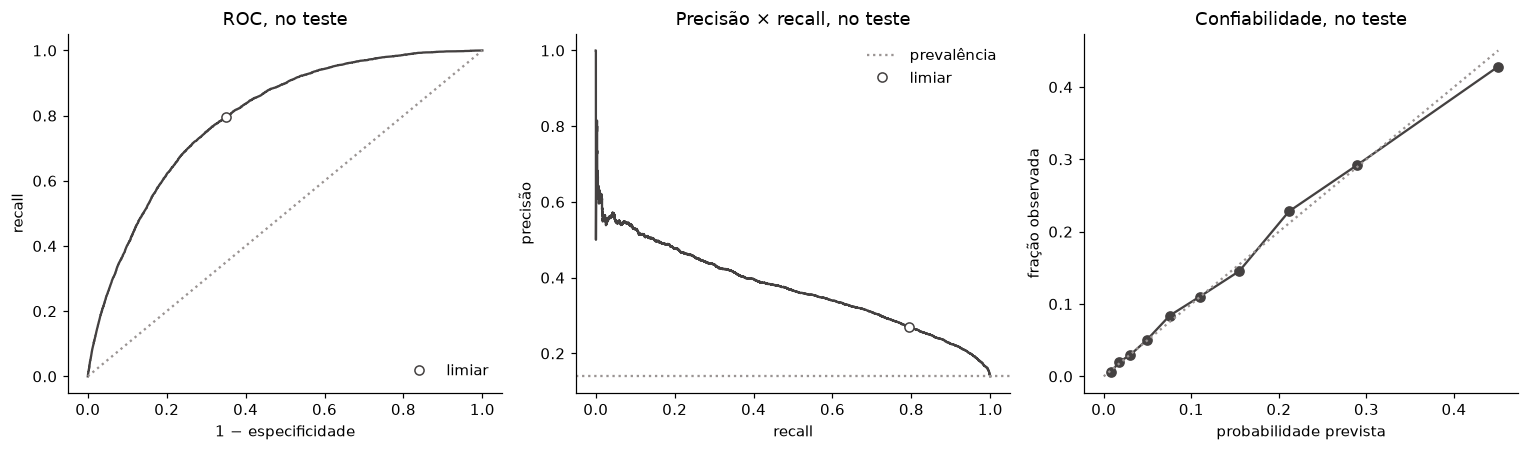

In [18]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.2))
fpr, tpr, _ = roc_curve(y_teste, p_teste)
ax1.plot(fpr, tpr, color='#444141')
ax1.plot([0, 1], [0, 1], ':', color='#9a9493')
ax1.plot(1 - no_limiar['especificidade'], no_limiar['recall'], 'o', color='#444141', mfc='white', label='limiar')
ax1.set(xlabel='1 − especificidade', ylabel='recall', title='ROC, no teste')
ax1.legend(frameon=False, loc='lower right')
ax2.plot(recalls, precisoes, color='#444141')
ax2.axhline(y_teste.mean(), linestyle=':', color='#9a9493', label='prevalência')
ax2.plot(no_limiar['recall'], no_limiar['precisao'], 'o', color='#444141', mfc='white', label='limiar')
ax2.set(xlabel='recall', ylabel='precisão', title='Precisão × recall, no teste')
ax2.legend(frameon=False)
observado, previsto = calibration_curve(y_teste, p_teste, n_bins=10, strategy='quantile')
ax3.plot(previsto, observado, 'o-', color='#444141')
ax3.plot([0, previsto.max()], [0, previsto.max()], ':', color='#9a9493')
ax3.set(xlabel='probabilidade prevista', ylabel='fração observada', title='Confiabilidade, no teste')
plt.tight_layout()
plt.show()

In [19]:
grupo_idade = pd.cut(X_teste['Faixa_Etaria'], [0, 5, 9, 13], labels=['18 a 44 anos', '45 a 64 anos', '65 anos ou mais'])
linhas = []
for nome, chave in (('sexo', X_teste['Sexo']), ('idade', grupo_idade)):
    for valor in chave.dropna().unique():
        mascara = (chave == valor).to_numpy()
        alvo, p = y_teste[mascara], p_teste[mascara]
        ponto = ponto_de_operacao(alvo, p, LIMIAR)
        linhas.append({'grupo': nome, 'valor': str(valor), 'n': int(mascara.sum()), 'prevalencia': alvo.mean(),
                       'probabilidade_media': p.mean(), 'roc_auc': roc_auc_score(alvo, p),
                       'recall': ponto['recall'], 'precisao': ponto['precisao'], 'encaminhados': ponto['encaminhados']})
pd.DataFrame(linhas).sort_values(['grupo', 'valor'], ignore_index=True)

,grupo,valor,n,prevalencia,probabilidade_media,roc_auc,recall,precisao,encaminhados
0,idade,18 a 44 anos,10962,0.0419,0.0404,0.8223,0.4161,0.2370,0.0735
1,idade,45 a 64 anos,21855,0.1345,0.1342,0.7909,0.7541,0.2679,0.3786
2,idade,65 anos ou mais,17919,0.2048,0.2069,0.7237,0.8744,0.2714,0.6599
3,sexo,Feminino,28531,0.1292,0.1300,0.8095,0.7840,0.2695,0.3758
4,sexo,Masculino,22205,0.1524,0.1519,0.7788,0.8061,0.2679,0.4586


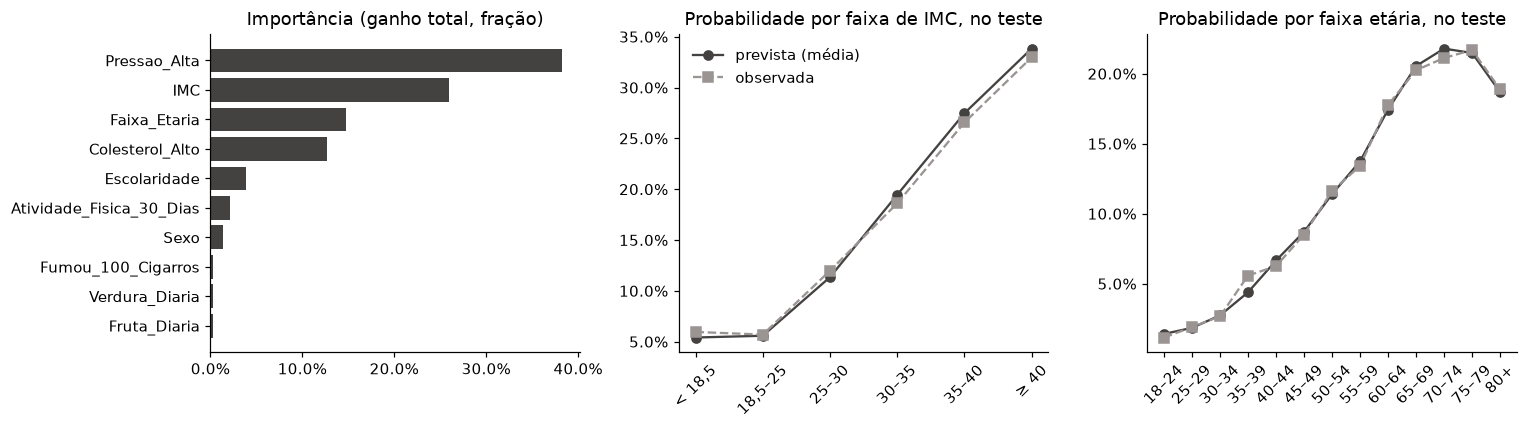

Pressao_Alta               0.3831
IMC                        0.2601
Faixa_Etaria               0.1480
Colesterol_Alto            0.1271
Escolaridade               0.0387
Atividade_Fisica_30_Dias   0.0209
Sexo                       0.0143
Fumou_100_Cigarros         0.0028
Verdura_Diaria             0.0026
Fruta_Diaria               0.0026
dtype: float64

In [20]:
# Importância por ganho, somada por entrada, e o sentido do efeito: a probabilidade média prevista no
# teste por faixa de IMC e por faixa etária tem de subir com as duas (conferência de sanidade).
estimador = modelo_final.calibrated_classifiers_[0].estimator if calibrar else modelo_final
nomes = [n.split('__', 1)[1] for n in estimador.named_steps['colunas'].get_feature_names_out()]
modelo_interno = estimador.named_steps['modelo']
if escolhido['modelo'] == 'XGBoost':
    ganho = modelo_interno.get_booster().get_score(importance_type='total_gain')
    importancia = pd.Series({nomes[int(k[1:])]: v for k, v in ganho.items()})
else:
    importancia = pd.Series(modelo_interno.booster_.feature_importance(importance_type='gain'), index=nomes)
importancia = (importancia / importancia.sum()).reindex(ENTRADAS).fillna(0).sort_values()

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4))
ax1.barh(importancia.index, importancia.values, color='#444141')
ax1.xaxis.set_major_formatter(PercentFormatter(1.0))
ax1.set_title('Importância (ganho total, fração)')
faixa_imc_teste = pd.cut(X_teste['IMC'], [0, 18.5, 25, 30, 35, 40, np.inf], right=False, labels=FAIXAS_IMC)
for ax, chave, titulo, rotulos in (
    (ax2, faixa_imc_teste, 'por faixa de IMC', None),
    (ax3, X_teste['Faixa_Etaria'], 'por faixa etária', ROTULO_IDADE),
):
    # reset_index: alinha com os arrays por posição e MANTÉM a ordem do categórico (o to_numpy a perderia)
    tabela = pd.DataFrame({'prevista': p_teste, 'observada': y_teste, 'chave': chave.reset_index(drop=True)})
    tabela = tabela.groupby('chave', observed=True)[['prevista', 'observada']].mean()
    x = np.arange(len(tabela))
    ax.plot(x, tabela['prevista'], 'o-', color='#444141', label='prevista (média)')
    ax.plot(x, tabela['observada'], 's--', color='#9a9493', label='observada')
    ax.set_xticks(x, [rotulos[i] for i in tabela.index] if rotulos else list(tabela.index), rotation=45)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f'Probabilidade {titulo}, no teste')
ax2.legend(frameon=False)
plt.tight_layout()
plt.show()
importancia.sort_values(ascending=False)

### Leitura

- No teste, as métricas ficam onde a validação cruzada as deixou e o recall no limiar fica perto do alvo: o modelo não foi escolhido olhando para o teste, e não há sinal de sobreajuste. A probabilidade continua calibrada — o Brier fica bem abaixo do de chutar a prevalência.
- **O limiar é um só, e a idade domina o risco.** Entre os mais jovens quase ninguém passa do limiar e o recall é baixo; entre os mais velhos, a maioria é encaminhada. Um limiar por faixa etária seria uma decisão de política de triagem, fora do escopo deste estudo — fica registrada como limitação. Entre os sexos, recall e precisão ficam próximos.
- Pressão alta, IMC, idade e colesterol concentram quase todo o ganho do modelo. A probabilidade média prevista acompanha a observada por faixa de IMC e por faixa etária — sobe com as duas e recua nas idades mais altas como o observado recua: o modelo não aprendeu nenhuma direção invertida.

## O que fica congelado para o CLI

O CLI de treino da vertente (`python -m app.diabetes.treino treinar`) reproduz exatamente o que a célula abaixo imprime: as entradas, o split, o algoritmo com os hiperparâmetros, o tratamento do desbalanceamento, a calibração e o critério do limiar. As métricas **publicadas** não são as desta página: são as do manifest (`artifacts/diabetes/manifest.json`), servidas pela API — o CLI retreina sobre o snapshot congelado do banco, e o CI confere que o modelo servido é o que esse treino produz.

In [21]:
# Os hiperparâmetros que as fábricas xgb()/lgbm() fixam, com os ajustes do escolhido por cima.
FIXADOS = {'n_estimators', 'learning_rate', 'max_depth', 'num_leaves', 'min_child_samples', 'subsample',
           'subsample_freq', 'colsample_bytree', 'objective', 'eval_metric', 'tree_method', 'random_state',
           'n_jobs', 'verbose'}
parametros_congelados = {
    k: v for k, v in fabrica_escolhida(**ajustes_escolhidos).get_params().items() if k in FIXADOS and v is not None
}
if tratamento == 'peso de classe':
    parametros_congelados['scale_pos_weight'] = float(razao)
CONGELADO = {
    'entradas': ENTRADAS,
    'split': {'test_size': 0.2, 'stratify': True, 'random_state': SEMENTE},
    'validacao_cruzada': {'n_splits': 5, 'shuffle': True, 'random_state': SEMENTE},
    'algoritmo': type(fabrica_escolhida()).__name__,
    'hiperparametros': parametros_congelados,
    'desbalanceamento': tratamento,
    'calibracao': 'isotonica (cv=3)' if calibrar else 'nenhuma',
    'limiar': {
        'criterio': f'maior limiar com recall >= {RECALL_ALVO} nas predições fora da dobra do treino',
        'recall_alvo': RECALL_ALVO,
        'valor_nesta_execucao': round(LIMIAR, 6),
    },
}
print(json.dumps(CONGELADO, ensure_ascii=False, indent=2))

{
  "entradas": [
    "Faixa_Etaria",
    "Sexo",
    "IMC",
    "Pressao_Alta",
    "Colesterol_Alto",
    "Fumou_100_Cigarros",
    "Atividade_Fisica_30_Dias",
    "Fruta_Diaria",
    "Verdura_Diaria",
    "Escolaridade"
  ],
  "split": {
    "test_size": 0.2,
    "stratify": true,
    "random_state": 42
  },
  "validacao_cruzada": {
    "n_splits": 5,
    "shuffle": true,
    "random_state": 42
  },
  "algoritmo": "XGBClassifier",
  "hiperparametros": {
    "objective": "binary:logistic",
    "colsample_bytree": 0.8,
    "eval_metric": "logloss",
    "learning_rate": 0.05,
    "max_depth": 3,
    "n_estimators": 300,
    "n_jobs": 8,
    "random_state": 42,
    "subsample": 0.8,
    "tree_method": "hist"
  },
  "desbalanceamento": "nenhum",
  "calibracao": "nenhuma",
  "limiar": {
    "criterio": "maior limiar com recall >= 0.8 nas predições fora da dobra do treino",
    "recall_alvo": 0.8,
    "valor_nesta_execucao": 0.125548
  }
}


## Limitações

- **Autodeclarado.** Diagnósticos, hábitos e o próprio IMC (calculado de peso e altura informados ao telefone) são o que a pessoa respondeu.
- **Transversal.** Uma resposta por pessoa, num momento só: associação, não causa. Quem já tem o diagnóstico pode ter mudado os hábitos depois dele.
- **O alvo é o diagnóstico recebido.** Quem tem diabetes e não sabe está entre os negativos: o modelo aprende "ter sido diagnosticado", e a triagem existe justamente para quem não foi. As entradas escolhidas para reduzir esse viés, não para eliminá-lo; o pré-diabetes conta como "não" (FONTE.md, divergência 1), e a pergunta do BRFSS não separa o tipo 1 do tipo 2.
- **Um limiar para todas as idades.** O risco cresce com a idade, e com um limiar só os mais jovens quase não são encaminhados e os mais velhos quase todos são (avaliação final). Um limiar por faixa etária é decisão de política de triagem, fora do escopo deste estudo.
- **Sem pesos e só casos completos.** A probabilidade está na escala da base, não na da população dos Estados Unidos — e menos ainda na do Brasil, onde hábitos, escolaridade e o próprio sistema de saúde são outros. Nenhuma validação externa foi feita.